<!-- d2l:prose id=hybrids-md-1 fw=all -->

# Hybrid Architectures


Every model in this chapter has improved *how* a fixed-size state is updated, from gates to selective dynamics to error-correcting delta rules, yet none of them can store more information than the state's size allows. When a user pastes a table of 64 product codes and prices into a prompt and asks for 20 of them, a Transformer looks back across its full KV cache and retrieves the exact tokens, whereas a purely recurrent model has only what it compressed into its fixed state before knowing which items would be queried. In-context retrieval (in few-shot prompting, retrieval-augmented generation, and code editing) is where fixed-state sequence models hit a hard ceiling.

The remedy adopted by the recurrent language models in production use is pragmatic: interleave a small fraction of full attention layers among the recurrent blocks. Below we establish two fundamental limits on fixed-state recall (an information-theoretic bit-counting bound and Welch's geometric lower bound on key overlap), compare pure `GatedDeltaNet`, pure attention, and a `GA` hybrid on multi-query associative recall and byte-level WikiText-103, ablate the short depthwise convolution that pairs adjacent key and value tokens, quantify inference KV-cache savings at 256K context length, and summarize all sequence memories covered in this chapter.

In [1]:
import math
import numpy as np
import torch
from torch import nn
from torch.nn import functional as F
from d2l import torch as d2l

<!-- d2l:prose id=hybrids-md-2 fw=all -->

## Limits of a Fixed-Size State

### Counting Bits

By the pigeonhole principle, a state of $M$ numbers stored at $b$ bits each has at most $2^{Mb}$ distinct configurations. To distinguish and reproduce all $V^k$ possible sequences of $k$ tokens drawn from a vocabulary of size $V$, the state must satisfy [@Jelassi.Brandfonbrener.Kakade.ea.2024]:

$$M b \ge k \log_2 V.$$

Thus the maximum number of tokens a fixed state can recall grows linearly with state size $M$ and is completely independent of context length $T$, whereas a Transformer's KV cache grows linearly with $T$ and never saturates.

In practice, linear matrix memories hit a geometric limit long before saturating their raw bit count. In our associative recall benchmark below, a sequence stores up to 64 pairs with keys drawn from 128 symbols and values from 4 symbols (at most $128 \times 2 = 256$ bits of table information, or $64 \times 2 = 128$ bits for the 64 values), while two `GatedDeltaNet` layers with 8 heads of $4 \times 4$ float32 states hold $256 \times 32 = 8{,}192$ bits—more than $30\times$ the required bits. Why does a matrix memory lose pairs well below its raw bit count?

### Overlapping Keys

Whether a matrix head $\mathbf{S} \in \mathbb{R}^{d_v \times d_k}$ is updated additively (that section) or via the delta rule toward the least-squares fit (that section), exact linear readout $\mathbf{S}\mathbf{k}_j = \mathbf{v}_j$ for arbitrary values requires the stored keys to be linearly independent—and $\mathbb{R}^{d_k}$ holds at most $d_k$ linearly independent vectors. Once the number of stored keys $m$ exceeds the head dimension $d_k$, the keys *must* overlap no matter how training chooses them.

**Proposition (Welch's Bound).** Let $\mathbf{k}_1, \ldots, \mathbf{k}_m$ be unit vectors in $\mathbb{R}^{d_k}$ with $m > d_k$. Then the average squared inner product over all distinct pairs $i \neq j$ is at least [@Welch.1974]:

$$\frac{m - d_k}{d_k\,(m - 1)}.$$

**Proof.** Let $\mathbf{G} = \sum_{i=1}^m \mathbf{k}_i \mathbf{k}_i^\top \in \mathbb{R}^{d_k \times d_k}$. Its trace is $\sum_{i=1}^m \|\mathbf{k}_i\|^2 = m$, so its $d_k$ eigenvalues sum to $m$. By Cauchy–Schwarz, the sum of its squared eigenvalues, which equals $\|\mathbf{G}\|_F^2 = \sum_{i,j} (\mathbf{k}_i^\top \mathbf{k}_j)^2$, is at least $m^2 / d_k$. Subtracting the $m$ diagonal terms $(\mathbf{k}_i^\top \mathbf{k}_i)^2 = 1$ leaves at least $m^2 / d_k - m = m(m - d_k)/d_k$ across the $m(m - 1)$ off-diagonal pairs. $\blacksquare$

In a head of dimension $d_k = 4$, $m = 64$ unit keys must have mean squared overlap at least $60 / (4 \times 63) \approx 0.24$—almost indistinguishable from random unit vectors ($1/d_k = 0.25$). Widening the head to $d_k = 16$ lowers the Welch floor to $48 / (16 \times 63) \approx 0.05$.

This predicts two clear experimental signatures on multi-query associative recall:

1. A pure `GatedDeltaNet` stack will degrade as the number of stored pairs $n$ grows past its state capacity, while quadrupling its per-layer state entries (from $8 \times 4^2 = 128$ to $2 \times 16^2 = 512$ at fixed width $d = 32$) will shift the degradation to roughly $4\times$ higher pair loads.
2. Replacing just one of the two recurrent blocks with full causal attention (`GA`) will eliminate the capacity drop entirely, because the attention layer retains every token in its cache.

## Recall with One Attention Layer

### Four Models

We test four two-block `d2l.SeqLM` models ($d = 32$) on multi-query associative recall (`num_keys=128`, `num_values=4`, loads $n \in \{4, 8, 16, 32, 64\}$):

- **`Gated DeltaNet` (`GG`):** 8 heads of size 4 ($128$ state entries/layer);
- **`Gated DeltaNet, 4x state` (`GG, num_heads=2`):** 2 heads of size 16 ($512$ state entries/layer, same parameter count);
- **`attention` (`AA`):** 2-head causal attention (`d2l.AttentionMixer`) with the same width-4 depthwise causal convolution on $(\mathbf{Q}, \mathbf{K}, \mathbf{V})$ and no positional encoding (`rope=False`);
- **`hybrid` (`GA`):** `GatedDeltaNet` in block 1 followed by `AttentionMixer` in block 2.

In [2]:
def recall_model(layout, num_heads=8, conv_width=4, num_hiddens=32):
    """SeqLM whose mixers are given by letters: G(ated DeltaNet) with
    num_heads heads, A(ttention) with two; tokens: 4 values, 128 keys, and
    the filler."""
    make = {'G': lambda: d2l.GatedDeltaNet(
                num_hiddens, num_heads, conv_width=conv_width,
                timescales=(256, 2048)),
            'A': lambda: d2l.AttentionMixer(num_hiddens, num_heads=2,
                                            conv_width=4, rope=False)}
    return d2l.SeqLM(4 + 128 + 1, num_hiddens, [make[c]() for c in layout])

<!-- d2l:prose id=hybrids-md-3 fw=all -->

### The Recall Sweep

We train two seeds of each architecture for 2,000 updates with `d2l.train_recall` and evaluate accuracy across pair loads.

In [3]:
arms = {'Gated DeltaNet': dict(layout='GG'), 'attention': dict(layout='AA'),
        'hybrid': dict(layout='GA'),
        'Gated DeltaNet, 4x state': dict(layout='GG', num_heads=2)}
recall = {}
for name, arm in arms.items():
    models = [recall_model(**arm) for _ in range(2)]
    recall[name] = [d2l.train_recall(model, num_keys=128) for model in models]
    print(f'{name:25s} {d2l.num_params(models[0]):,} parameters')

Gated DeltaNet            37,989 parameters


attention                 34,821 parameters


hybrid                    36,405 parameters


Gated DeltaNet, 4x state  37,197 parameters


<!-- d2l:prose id=hybrids-md-4 fw=all -->

We now average the recall curves across the two runs of each arm and plot accuracy as a function of the number of stored pairs $n \in \{4, 8, 16, 32, 64\}$:

pairs                               4          8         16         32         64
Gated DeltaNet              1.00/0.99  0.98/0.94  0.87/0.82  0.70/0.64  0.56/0.51
attention                   1.00/1.00  1.00/1.00  1.00/1.00  1.00/1.00  1.00/1.00
hybrid                      1.00/1.00  1.00/1.00  1.00/1.00  1.00/1.00  1.00/1.00
Gated DeltaNet, 4x state    1.00/1.00  1.00/1.00  1.00/1.00  1.00/0.99  0.97/0.97


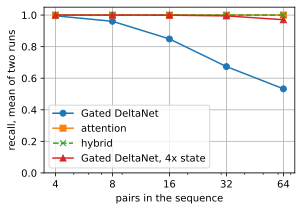

In [4]:
pairs = list(recall['hybrid'][0])
runs = {name: np.array([[run[n] for n in pairs] for run in two])
        for name, two in recall.items()}  # Two rows, one per run
d2l.plot(pairs, [r.mean(0) for r in runs.values()], 'pairs in the sequence',
         'recall, mean of two runs', legend=list(runs), xscale='log',
         ylim=(0, 1.05), fmts=('-o', '-s', '--x', '-^'), figsize=(4.5, 3),
         legend_loc='lower left')
d2l.plt.xticks(pairs, pairs)  # Ticks at the numbers of pairs
print(f'{"pairs":25s}', ''.join(f'{n:>11d}' for n in pairs))
for name, r in runs.items():
    print(f'{name:25s}', ''.join(f'{a:6.2f}/{b:.2f}' for a, b in r.T))

<!-- d2l:prose id=hybrids-md-5 fw=all -->

Both predictions hold:

1. **State capacity scaling in `GatedDeltaNet`:** With 128 state entries/layer (`GG`), recall drops from about $1.00$ at 4 pairs to between $0.6$ and $0.7$ at 32 pairs and about $0.5$ at 64 pairs. Quadrupling the state to 512 entries/layer (`Gated DeltaNet, 4x state`) keeps recall near $1.00$ through 32 pairs. At 64 pairs it recalls most pairs, between about $0.8$ and $1.0$ depending on the run.
2. **One attention layer restores exact recall:** Both `attention` (`AA`) and the `hybrid` (`GA`) achieve $1.00$ recall across every load up to 64 pairs in every run—mirroring the large-scale findings of @Waleffe.Byeon.Riach.ea.2024 .

### The Short Convolution

Why did we include a width-4 depthwise causal convolution in front of our recurrent and attention mixers? In associative recall, each value arrives at token $t$ immediately *after* its key at token $t - 1$. Without local token mixing (`conv_width=1`), a single matrix-state layer at step $t$ sees only the value token and cannot bind it to the preceding key token. Let us ablate the convolution by setting `conv_width=1` in `GG`:

In [5]:
no_conv = [d2l.train_recall(recall_model('GG', conv_width=1), num_keys=128)
           for _ in range(2)]  # Width 1: only scales and shifts each channel
print(f'{"pairs":25s}', ''.join(f'{n:>11d}' for n in pairs))
for name, (a, b) in [('Gated DeltaNet', recall['Gated DeltaNet']),
                     ('without the convolution', no_conv)]:
    print(f'{name:25s}', ''.join(f'{a[n]:6.2f}/{b[n]:.2f}' for n in pairs))

pairs                               4          8         16         32         64
Gated DeltaNet              1.00/0.99  0.98/0.94  0.87/0.82  0.70/0.64  0.56/0.51
without the convolution     0.81/0.84  0.64/0.69  0.51/0.55  0.42/0.45  0.36/0.38


<!-- d2l:prose id=hybrids-md-6 fw=all -->

Removing the width-4 causal convolution degrades recall at every single load (by roughly $10$ to $35$ percentage points, dropping even 4-pair recall to between $0.8$ and $0.9$).

## Language Modeling at Equal Size

How do pure `GatedDeltaNet` (`GGGG`), a 3-to-1 hybrid (`GGGA`), and pure causal `attention` (`AAAA`) compare on our byte-level WikiText-103 benchmark (`d2l.SeqLM`, 4 blocks at width $d = 256$)? We ask twice: first on the 128-byte windows used throughout this chapter, and then on windows of 1,024 bytes, to see whether a longer context separates a fixed state from a growing cache. Both times we train for 8,000 steps and not for the 1,000 steps of the earlier sections, because a model learns to use distant context late in training. The losses below are therefore lower than those of the earlier text tables and cannot be compared with them.

### Short Windows

We first load the 128-byte `WikiText103` dataset:

In [6]:
data = d2l.WikiText103(batch_size=64, num_steps=128)

<!-- d2l:prose id=hybrids-md-7 fw=all -->

The comparison needs one more arm to be fair. Mamba, gated linear attention, and Gated DeltaNet all mix neighboring tokens with a width-4 causal convolution before their recurrence, while the attention mixer of our text benchmarks has had none. A lead of `GatedDeltaNet` over `attention` could therefore belong to the convolution rather than to the memory. We give attention the same convolution in a fourth arm, as we did in the recall experiment.

To this end, `text_model(layout, d)` constructs a 4-block `d2l.SeqLM` whose mixers follow a four-letter `layout` string of `'G'` (`GatedDeltaNet`, 4 heads), `'A'` (`AttentionMixer`, 8 heads), `'C'` (the same attention behind a width-4 causal convolution), and `'R'` (a `GRU`, for the longer windows below):

In [7]:
torch.set_float32_matmul_precision('high')  # fp32 matmuls may use tf32
text_mixers = {'R': lambda d: d2l.Recurrent(d2l.init_lecun(
                   nn.GRU(d, d, batch_first=True))),
               'G': lambda d: d2l.GatedDeltaNet(d, num_heads=4),
               'A': lambda d: d2l.AttentionMixer(d, num_heads=8),
               'C': lambda d: d2l.AttentionMixer(d, num_heads=8,
                                                 conv_width=4)}

def text_model(layout, d):  # 256 byte values; one block per letter
    return d2l.SeqLM(256, d, [text_mixers[c](d) for c in layout]).to(
        d2l.try_gpu())

<!-- d2l:prose id=hybrids-md-8 fw=all -->

We train two runs each of `'GGGG'`, `'GGGA'`, `'AAAA'`, and `'CCCC'` at width $d = 256$ for 8,000 steps via `d2l.text_table`:

In [8]:
arms = {'Gated DeltaNet': ('GGGG', 256), 'hybrid': ('GGGA', 256),
        'attention': ('AAAA', 256),
        'attention, conv': ('CCCC', 256)}  # Width 256, four blocks each
trained = d2l.text_table(text_model, arms, data, num_steps=8000)

                             validation        0-15       16-63      64-127   ms/step


Gated DeltaNet    3,573,536 1.161/1.158 1.397/1.399 1.132/1.128 1.124/1.120 48/50


hybrid            3,501,848 1.153/1.154 1.399/1.398 1.123/1.124 1.114/1.114 44/43


attention         3,286,784 1.182/1.185 1.410/1.412 1.152/1.155 1.146/1.151 21/21


attention, conv   3,302,144 1.150/1.154 1.397/1.397 1.121/1.124 1.110/1.116 26/26


<!-- d2l:prose id=hybrids-md-9 fw=all -->

On 128-byte windows three of the four arms finish together: `Gated DeltaNet` at about $1.16$ nats per byte, and the `GGGA` hybrid and attention with the convolution at about $1.15$. Only `attention` without the convolution stands apart, about $0.03$ behind at $1.18$. At this length the loss is dominated by local syntax: it hardly changes after the first 16 bytes of a window (that section), so the table mostly measures how well a mixer combines neighboring bytes.

The convolution thus accounts for the whole deficit of plain attention. With it, attention is level with the hybrid. Both are ahead of `Gated DeltaNet` by $0.01$ at most, which is about what separates two runs of the same arm, so we read no ranking into it. On short windows neither the matrix memory nor the cache has an advantage that local mixing does not explain, and the hybrid's single attention layer adds nothing that we can measure. That layer matters where exact long-range lookup is needed (Exercise 5). Does it matter on real text once the windows are long enough?

### Long Windows

Windows of 128 bytes cannot show what a fixed state loses against a growing cache, nor what a vector state loses against a matrix memory. We therefore train four mixers on windows of 1,024 bytes: a stack of `GRU`s (`'RRRR'`), `Gated DeltaNet`, the `GGGA` hybrid, and attention with the convolution. The batch size drops from 64 to 8, so that every step still sees the same number of bytes and the 8,000 steps the same amount of text.

In [9]:
long_data = d2l.WikiText103(batch_size=8, num_steps=1024)  # Same bytes/step
long_arms = {'GRU': ('RRRR', 256), 'Gated DeltaNet': ('GGGG', 256),
             'hybrid': ('GGGA', 256), 'attention, conv': ('CCCC', 256)}
long_trained = d2l.text_table(text_model, long_arms, long_data,
                              num_steps=8000)  # Long context needs training

                             validation       0-127     128-511    512-1023   ms/step


GRU               3,817,216 1.088/1.088 1.146/1.144 1.084/1.086 1.075/1.075 119/119


Gated DeltaNet    3,573,536 1.116/1.122 1.183/1.185 1.115/1.120 1.100/1.108 64/63


hybrid            3,501,848 1.083/1.083 1.182/1.184 1.082/1.083 1.058/1.057 54/55


attention, conv   3,302,144 1.073/1.065 1.199/1.190 1.076/1.070 1.040/1.030 32/32


<!-- d2l:prose id=hybrids-md-10 fw=all -->

The average over a window hides where in the window each model gains. A model that uses its whole context keeps improving as the position grows, whereas one that summarizes only the recent bytes stops improving early. To tell the two apart, we average the validation loss of the two runs over bands of positions $[a, 2a)$ that double in length, from bytes 16–31 up to bytes 512–1,023:

positions             16-31     32-63    64-127   128-255   256-511  512-1023
GRU                   1.118     1.097     1.100     1.079     1.088     1.075
Gated DeltaNet        1.161     1.135     1.137     1.113     1.119     1.104
hybrid                1.167     1.133     1.130     1.089     1.079     1.057
attention, conv       1.192     1.148     1.138     1.090     1.065     1.035


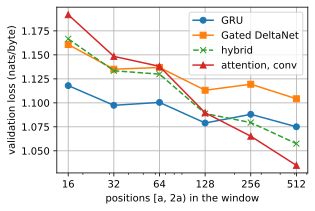

In [10]:
losses = {name: np.mean([d2l.loss_by_position(model, long_data)
                         for model in models], 0)  # Mean of the two runs
          for name, models in long_trained.items()}
starts = [16, 32, 64, 128, 256, 512]  # Bands [a, 2a) of positions
bands = {name: [loss[a:2 * a].mean() for a in starts]
         for name, loss in losses.items()}
d2l.plot(starts, list(bands.values()), 'positions [a, 2a) in the window',
         'validation loss (nats/byte)', legend=list(bands), xscale='log',
         fmts=('-o', '-s', '--x', '-^'), figsize=(4.5, 3))
d2l.plt.xticks(starts, starts)  # Ticks at the first position of each band
print(f'{"positions":16s}', ''.join(f'{f"{a}-{2 * a - 1}":>10s}'
                                   for a in starts))
for name, band in bands.items():
    print(f'{name:16s}', ''.join(f'{v:10.3f}' for v in band))

<!-- d2l:prose id=hybrids-md-11 fw=all -->

Longer windows help every model that we trained at both lengths. `Gated DeltaNet` ends between $1.11$ and $1.12$ and the hybrid between $1.07$ and $1.08$, against $1.16$ and $1.15$ on windows of 128 bytes. Attention with the convolution ends at about $1.07$ in most runs. About one run in five ends near $1.12$ instead, for a reason that we give below. The `GRU` reaches $1.09$. It is the slowest arm by a wide margin, at about twice the time per step of the next slowest or more, because it alone processes a window one step after another.

The three arms that were level on short windows are level no longer, and the columns of the table show where they part. From the first 128 bytes of a window to the last 512, the loss of the `GRU` falls by about $0.07$ and that of `Gated DeltaNet` by about $0.08$. The hybrid gains about $0.13$, and attention, in most runs, about $0.16$. The plot locates the gain more closely. Up to byte 127 the fixed states hold their own: the `GRU` is lowest in every band, attention is highest in the first bands, and the hybrid cannot be told from pure `Gated DeltaNet`. Beyond byte 128 the `GRU` and `Gated DeltaNet` gain little more, about $0.03$ by the last band. The hybrid keeps falling. It leaves `Gated DeltaNet` behind at byte 128, and from byte 256 on it is below the `GRU` as well. At bytes 512–1,023 it leads `Gated DeltaNet` by about $0.05$ and the `GRU` by about $0.02$. All of this lead comes from the one attention layer in its fourth block.

Attention falls the furthest, though not in every run. In most runs it ends at $1.03$ to $1.04$ on bytes 512–1,023, about $0.02$ ahead of the hybrid and the best of the four models. About one run in five lags. It ends at around $1.12$ overall and at about $1.10$ in the last band, no better than `Gated DeltaNet`. The plot shows the mean of the two runs in the table, so where one of them is such a run, the attention curve ends above the hybrid's and not below it.

The two kinds of run differ by a single event. For the first thousand steps or so, all runs follow the same training loss. In most runs the loss then falls suddenly by about $0.05$, at some step between 1,000 and 5,000. A lagging run declines smoothly and never shows this drop. The drop is the moment at which attention learns to copy. Text repeats itself: a name, a date, or a phrase often recurs within a kilobyte. A model that finds the earlier occurrence of the bytes it has just read, and predicts the byte that followed them there, gains at every such repeat. @Olsson.Elhage.Nanda.ea.2022 call this circuit an *induction head*, and we met it in that section. We can test for it directly. On windows that contain the same passage of 512 bytes twice, a run that has had its drop predicts the second copy at $0.6$ to $0.8$ of the loss of the first. A lagging run predicts both copies at nearly the same loss, through all 8,000 steps. On the first 128 bytes of a window, where there is little to copy from, the two kinds of run cannot be told apart.

A lagging run is not unstable. Its loss does not diverge, and its gradients are as large as those of the other runs. It is simply late. The step at which the circuit forms varies with the seed, and the cosine schedule leaves little learning rate after about step 6,000, so a run that has not formed the circuit by then does not form it at all. The short convolution helps here as it did in the recall task: without it, most runs have had no drop by step 5,000. We also tried other learning rates, no weight decay, and a different number of attention heads. The misses became rarer in one case and disappeared in none. Sudden drops of this kind are typical when a network must assemble a circuit from parts that are of little use on their own, and they are a good reason to train more than one seed before ranking two architectures.

With a long context and enough training, then, text shows a weaker form of what the recall task showed. The growing cache gains the most from distant bytes, a single attention layer among three recurrent ones recovers a good part of that gain, and a fixed state alone gains the least. On windows of 128 bytes there are no distant bytes to use, which is why the short-window table cannot show this.

## Inference Memory

During autoregressive generation, per-sequence memory determines both maximum serving batch size and memory-bandwidth-bound decoding speed:

- **Grouped-query attention layer** ($n_\textrm{kv} = 8$ key–value heads of dimension $d_\textrm{head} = 128$ in 16-bit floats): stores $2 \times n_\textrm{kv} \times d_\textrm{head} \times 2 = 4\textrm{ KB}$ *per token*—reaching $512\textrm{ MB}$ per layer at $T = 128\textrm{K}$ tokens.
- **Recurrent / matrix-state layer** (e.g., Mamba-2 at width $4{,}096$ with $8{,}192$ channels and state dimension $128$ in 16-bit floats): stores a fixed $8{,}192 \times 128 \times 2 = 2\textrm{ MB}$ *regardless of context length* (overtaken by the attention layer's KV cache after just $512$ tokens).

In a hybrid architecture, only the attention layers accumulate a growing KV cache (the figure). A 32-layer model with 4 attention layers (1 in 8, as in Jamba [@Lieber.Lenz.Bata.ea.2024]) cuts the 256K-token cache from $32\textrm{ GB}$ to $4\textrm{ GB}$, while 3-to-1 Gated DeltaNet hybrids such as Qwen3-Next [@Qwen.Team.2025] and Kimi Linear [@Kimi.Team.2025b] reduce the KV cache by $4\times$.

![Memory held per sequence during generation, against context length, for a 32-layer model with grouped-query attention (8 key–value heads of dimension 128) and Mamba-2-sized recurrent states, in 16-bit numbers. A transformer's cache reaches 32 GB at 256K tokens; a purely recurrent model stays at 64 MB at every length; a hybrid with 4 attention layers holds an eighth of the transformer's cache.](../img/mdl-modernrnn-hybrid-cache.svg)

## The Chapter's Memories Compared

the table compares every sequence mixer built in this chapter alongside causal attention and the hybrid (with $d$ denoting model width, $N$ state dimension, $H = 2d$ expanded channels in Mamba, $h$ number of heads, and $T$ sequence length).

<!-- tbl-caption:The memories of this chapter. Text: validation loss in nats per byte on byte-level WikiText-103, windows of 128 bytes, two runs per model; parameters in parentheses. The models of this section were trained for 8,000 steps and the others for 1,000, so only losses with the same number of steps can be compared. On windows of 1,024 bytes after 8,000 steps, attention with the convolution leads in most runs, ahead of the hybrid, the GRU, and Gated DeltaNet. -->

| Memory | State per layer at generation | Training | Synthetic task | Text |
| :-- | :-- | :-- | :-- | :-- |
| LSTM, GRU | $2d$, $d$ | one step after another | gates that start near one keep a symbol for 200 steps; started at one half, they lose it by 50 | 1.29 to 1.30 (4.3 M, 3.8 M) |
| minGRU | $d$ | scan | at chance after 100 steps; with the timescales of S4D, recalls after 1,000 | 1.34 to 1.35 (2.8 M) |
| S4D | $dN$ | convolution or scan | recalls after 1,000 steps; at most one in five on selective copying | not trained |
| Mamba | $HN$ | scan | 0.98 or more on selective copying | 1.30 (4.0 M) |
| gated linear attention | $d^2/h$ | chunks | about half of 64 pairs with 128 entries, more with 512 | not trained |
| Gated DeltaNet | $d^2/h$ | chunks with a triangular solve | 0.95 or more of rewritten keys, against about 0.9 for gated linear attention | 1.16 after 8,000 steps (3.6 M) |
| attention | $2dT$ | fused attention over all positions | every pair at every load | 1.38 to 1.39; after 8,000 steps 1.18, and 1.15 with the width-4 convolution (3.3 M) |
| hybrid | recurrent states plus $2dT$ per attention layer | both | every pair, with attention in one of two blocks | 1.15 after 8,000 steps (3.5 M) |

Reading across the columns summarizes the design trade-offs:

- For **low-power streaming or continuous sensor/audio processing** where exact lookup of arbitrary past tokens is not required, classical gated recurrences or selective SSMs provide compact $O(1)$-state processing.
- For **long-context foundation models**, interleaving chunk-parallel delta-rule matrix recurrences (`GatedDeltaNet`) or selective SSMs (`Mamba-2`) with a small ratio of full attention layers ($1{:}3$ to $1{:}7$) combines parallel linear-time training, $4\times$–$8\times$ smaller inference KV caches, and exact content-addressable recall.

## Summary

A fixed-size state of $M$ numbers at $b$ bits each can distinguish at most $2^{Mb}$ histories ($Mb \ge k \log_2 V$ to recall $k$ tokens from vocabulary $V$). In matrix-state layers, capacity is constrained even earlier by geometry: by Welch's bound, $m > d_k$ unit keys in $\mathbb{R}^{d_k}$ must have average squared overlap at least $(m - d_k)/(d_k(m - 1))$, causing cross-key interference under both additive and delta-rule updates. On multi-query associative recall, a pure `GatedDeltaNet` model degrades once pair count outgrows its state entries, whereas quadrupling state entries scales capacity proportionally and replacing a single recurrent block with full attention (`GA`) restores $100\%$ recall across all loads. A width-4 causal convolution in front of the mixer is essential so adjacent key and value tokens can bind within a single layer. On byte-level text the differences are smaller, and they depend on the length of the window. On windows of 128 bytes, `Gated DeltaNet`, the hybrid, and attention with the convolution finish within about $0.01$ nats per byte of one another after 8,000 steps, and the deficit of plain attention, about $0.03$, disappears once it has the same convolution. On windows of 1,024 bytes the models separate beyond byte 128: attention gains the most from distant context in most runs, the hybrid follows, and pure `Gated DeltaNet` gains the least. During generation, only the attention layers of a hybrid require a growing KV cache, cutting inference cache memory in proportion to the fraction of attention layers.

## Exercises

1. **The counting bound.** A model reads a string of $k$ tokens from a
   vocabulary of $V$ and must then reproduce it.
    1. Prove the equation for a model whose state between reading
       and writing has $M$ numbers of $b$ bits and whose output is a
       deterministic function of that state.
    1. Suppose instead that the model may output a wrong string with
       probability at most $\epsilon$ when the string is drawn uniformly.
       Show that $Mb \ge k \log_2 V + \log_2(1 - \epsilon)$. (Hint: count
       the strings that each state can decode correctly.)
    1. How many tokens of a vocabulary of 50,000 can a model with 48 layers
       of Mamba-2 state, 2 MB each in 16-bit numbers, copy at most? Why does
       no model of this size come close in practice?

1. **Memory for many users.** A GPU with 80 GB serves a model of 32
   layers, with the cache sizes of the figure, after 16 GB of
   the GPU's memory are taken by the weights.
    1. How many sequences of 128K tokens can the GPU serve at once with the
       transformer, the hybrid with 4 attention layers, and the recurrent
       model?
    1. Grouped-query attention with fewer key–value heads, and 8-bit
       numbers for the cache, each halve the cache. Apply both to the
       transformer and to the hybrid, and repeat the count. Which of the two
       changes could also shrink the hybrid's recurrent states, and what
       share of the hybrid's memory do those states take after both
       changes?

1. **Overlap and training.**
    1. How much better than random keys can training make the keys of a
       head? Divide the bound the equation by $1/d_k$, the mean
       squared overlap of random unit keys, and evaluate the ratio for 64
       keys in dimensions 4, 8, 16, and 32. In which of these heads can
       trained keys be clearly better than random ones?
    1. [code] Train the small Gated DeltaNet model of the sweep with 4,000
       and 8,000 updates (`num_updates` of `d2l.train_recall`). Does its
       recall of 32 and 64 pairs approach the hybrid's? What does the
       answer say about whether the small model lacks training or
       capacity?
    1. [code] Draw the keys from 64 and from 512 possible ones (`num_keys`,
       with the vocabulary of `recall_model` changed to match). A sequence
       still stores at most 64 pairs. Why can the number of possible keys
       change recall at all?

1. [code] **Where and how much attention?**
    1. Train the hybrid `AG`, with attention in the first block, and
       compare its recall with that of `GA`. Does the position of the
       attention layer matter? Consider which layer can bring each key
       together with the value that follows it.
    1. Train four-block models `GGGG`, `GGGA`, and `GAGA` of the same
       width. Do two more recurrent layers move the recall curve as far as
       four times the state per layer did, and does one attention layer
       among four still recall every pair?

1. [code] **Recall in text.** In the validation windows of byte-level
   WikiText-103, mark the positions whose byte completes a string of at
   least eight bytes that already occurred earlier in the same window.
    1. Compare the loss of the trained Gated DeltaNet, hybrid, and
       attention models (`trained`) at the marked positions and at all
       other positions. Does attention's advantage on recall show up where
       text repeats itself?
    1. Repeat with windows of 512 bytes (`num_steps=512`, with fewer
       windows per step). How does the share of marked positions change,
       and with it the difference between the models?

1. [code] **Watching the copy circuit form.** Build validation windows of
   1,024 bytes whose second half repeats the first. Train attention with
   the convolution (`'CCCC'`) on ordinary windows of 1,024 bytes, and
   every 250 steps record the training loss and the ratio of the loss on
   the second half of the repeated windows to the loss on the first.
    1. At which step does the ratio fall below 1, and does the training
       loss drop at the same step?
    1. Repeat with several seeds. How much does the step of the drop vary,
       and what does a run look like that has no drop within 8,000 steps?

[Discussions](https://d2l.discourse.group/t/36785)